## image-to-coco-json-converter

- This code transforms segmentation mask images to annotation JSON files as per the MS COCO format http://cocodataset.org/#format-data
- https://github.com/chrise96/image-to-coco-json-converter/tree/master?tab=readme-ov-file
- https://www.immersivelimit.com/tutorials/create-coco-annotations-from-scratch

- 2024 0ctober 12 understood and verified JS

create_sub_mask_annotation() は MultiPolygon を直接返すようにする

images_annotations_info() 側は既存の if category_id in multipolygon_ids: の分岐を活かす

In [1]:
import importlib

In [2]:
import glob

from src.create_annotations import *

im_size =256    ################ This is important. you have to decide the size to crop.


species_list = ['acapod', 'alllit', 'burspi', 'euclon', 'exostr', 'hakdac']

# Label ids of the dataset
category_ids = {
    "stuff" : 0,
    "vessel": 1,
    "ray": 2,
    "fiber": 3,
    "parenchyma": 4
}

# Define which colors match which categories in the images
category_colors = {
    "(255, 255, 255)": 1, # uco
    "(191, 191, 191)": 2, # ray
    "(127, 127, 127)": 3, # fiber
    "(63, 63, 63)": 4, # parenchyma
    "(0, 0, 0)": 0 # stuff
}

# # Label ids of the dataset
# category_ids = {
#     "stuff" : 0,
#     "unknown": 1,
# }

# # Define which colors match which categories in the images
# category_colors = {
#     "(255, 255, 255)": 1, # unknown
#     "(0, 0, 0)": 0 # stuff
# }
# Define the ids that are a multiplolygon. In our case: wall, roof and sky
multipolygon_ids = []

# Get "images" and "annotations" info 
def images_annotations_info(maskpath):
    # This id will be automatically increased as we go
    annotation_id = 0
    image_id = 0
    annotations = []
    images = []
    
    for mask_image in glob.glob(maskpath + "*.png"):
        # The mask image is *.png but the original image is *.jpg.
        # We make a reference to the original file in the COCO JSON file
        original_file_name = os.path.basename(mask_image).split(".")[0] + ".png"

        # Open the image and (to be sure) we convert it to RGB
        mask_image_open = Image.open(mask_image).convert("RGB")
        w, h = mask_image_open.size
        print(np.unique(np.array(mask_image_open).flatten()))
        # "images" info 
        image = create_image_annotation(original_file_name, w, h, image_id)
        images.append(image)

        sub_masks = create_sub_masks(mask_image_open, w, h)
        
        for color, sub_mask in sub_masks.items():
            category_id = category_colors[color]

            # "annotations" info
            polygons, segmentations = create_sub_mask_annotation(sub_mask)

            # Check if we have classes that are a multipolygon
            if category_id in multipolygon_ids:
                # Combine the polygons to calculate the bounding box and area
                multi_poly = MultiPolygon(polygons)
                                
                annotation = create_annotation_format(multi_poly, segmentations, image_id, category_id, annotation_id)

                annotations.append(annotation)
                annotation_id += 1
            else:
                for i in range(len(polygons)):
                    # Cleaner to recalculate this variable
                    segmentation = [np.array(polygons[i].exterior.coords).ravel().tolist()]
                    
                    annotation = create_annotation_format(polygons[i], segmentation, image_id, category_id, annotation_id)
                    
                    annotations.append(annotation)
                    annotation_id += 1
        image_id += 1
        # print(image_id)
    return images, annotations, annotation_id

if __name__ == "__main__":
    for species_name in species_list:
        for keyword in ["test", "valid", "train"]:
            mask_path = f"dataset/{species_name}/png_{im_size}_thin/mask/{keyword}/"

            coco_format = get_coco_json_format()
            coco_format["info"] = info()
            coco_format["categories"] = create_category_annotation(category_ids)

            coco_format["images"], coco_format["annotations"], annotation_cnt = images_annotations_info(mask_path)

            out_json_path = f"dataset/{species_name}/png_{im_size}_thin/image/{keyword}/{keyword}_annot_coco_{im_size}.json"
            with open(out_json_path, "w") as outfile:
                json.dump(coco_format, outfile)

            print(f"Created {annotation_cnt} annotations for images in folder: {mask_path}")



[  0  63 255]
[  0  63 127 191]
[  0  63 127 255]
[  0 127]
[  0  63 127 255]
[  0  63 127 255]
[  0  63 127 191 255]
[  0  63 127 255]
[  0  63 127 191 255]
[  0  63 127 255]
[  0  63 127 191 255]
[  0  63 127 255]
[  0  63 127 191 255]
[  0  63 127 255]
[  0  63 127 255]
[  0  63 127 255]
[  0 127]
[  0  63 127 191 255]
[  0  63 127 255]
[  0  63 127 191]
[  0  63 127 191 255]
[  0  63 127 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
Created 1182 annotations for images in folder: dataset/acapod/png_256_thin/mask/test/
[  0  63 127 255]
[  0  63 127 255]
[  0  63 127 255]
[  0  63 127 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 255]
[  0  63 127 255]
[  0  63 127 191]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0 127 191]
[  0  63 127 191 255]
[  0  63 127 255]
[  0  63 127 191 255]
[  0  63 127 191 255]
[  0  63 127 255]
[  0  63 127 255]
[  0  63 127 191 255]
[  0  63 127 191]
[  0  63 127 191

loading annotations into memory...
Done (t=0.02s)
creating index...
index created!


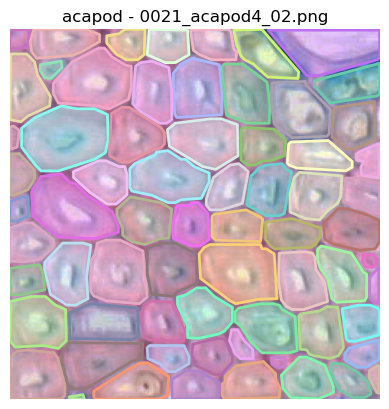

In [3]:
from pycocotools.coco import COCO
import matplotlib.pyplot as plt

# === 使用する種名を指定 ===
species_name = "acapod"  # <- 必要に応じて変更してください

# === アノテーションファイルのパス ===
anno_path = f"dataset/{species_name}/png_{im_size}_thin/image/train/train_annot_coco_{im_size}.json"
coco = COCO(anno_path)

# === 可視化対象の画像IDを選ぶ ===
img_id = coco.getImgIds()[2]  # 任意のindex
img_info = coco.loadImgs(img_id)
img_file = img_info[0]['file_name']
img_path = f"dataset/{species_name}/png_{im_size}_thin/image/train/{img_file}"

# === アノテーションを取得 ===
anno_ids = coco.getAnnIds(img_id)
annos = coco.loadAnns(anno_ids)

# === アノテーションを画像上に描画 ===
img = plt.imread(img_path)
plt.imshow(img)
coco.showAnns(annos)
plt.axis('off')
plt.title(f"{species_name} - {img_file}")
plt.show()


The end of script.